# Income–Consumption Gap and U.S. Household Demand

**Historical 1959–2009 consumer-facing macro factor falsification** | Prepared 2026-10-28 | **NOT PIT / NOT INDUSTRY-SPECIFIC / NOT EQUITY ALPHA**

This is an independently readable, 15-chapter empirical paper. A real-consumption aggregate is *not* a direct measure of NAICS 44–45 retail sales, company fundamentals, or investable returns.

## 01. Abstract

**Primary question:** Does a one-quarter-stale real disposable-income growth premium over real household consumption growth improve four-quarter-ahead real personal consumption expenditure (PCE) growth forecasts beyond transparent baselines? The null is zero incremental forecast accuracy. All observations are a single 2009 snapshot, not historical point-in-time release vintages. We explicitly allow a negative result.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
from IPython.display import display, Image
import analysis as A
ROOT=Path.cwd(); raw=A.load_raw(); panel=A.build_panel(raw); pred=A.walk_forward(panel)
metrics=json.loads((ROOT/'results/metrics.json').read_text()); print('Snapshot rows:',len(raw),'Panel rows:',len(panel),'OOS origins:',len(pred))

Snapshot rows: 203 Panel rows: 194 OOS origins: 126


In [2]:
print('Historical period:',raw.date.iloc[0],raw.date.iloc[-1]); print('OOS period:',pred.date.iloc[0],pred.date.iloc[-1]);print('Evidence status:',metrics['status'])

Historical period: 1959Q1 2009Q3
OOS period: 1977Q2 2008Q3
Evidence status: REPRODUCED RETROSPECTIVE CONSUMER-DEMAND MACRO PILOT — NOT PIT / NOT INDUSTRY-SPECIFIC / NOT EQUITY ALPHA


## 02. Research Design & Hypotheses

**H1 (income catch-up):** household spending may adjust upward after income growth outpaces consumption growth. **H2 (incremental):** the gap improves forecast RMSE versus macro controls and a simple mean. **H3 (robustness):** improvement survives time dependence, vintage-buffer variation, economic regimes and factor-weight perturbations. Counterthesis: saving motives, credit conditions and shocks make the gap uninformative. Primary horizon is four quarters, with predeclared one-quarter observation buffer.

In [3]:
print('Null: control-minus-augmented OOS RMSE <= 0; positive gain supports H2.');print('Horizon',A.BASE_HORIZON,'quarters; minimum train',A.MIN_TRAIN)

Null: control-minus-augmented OOS RMSE <= 0; positive gain supports H2.
Horizon 4 quarters; minimum train 65


In [4]:
print('Training target release purge: max(train origin) + horizon <= forecast origin:',bool((pred.train_last_origin+4<=pred.origin).all()))
display(pred[['date','origin','train_last_origin','train_n']].head(6))

Training target release purge: max(train origin) + horizon <= forecast origin: True


,date,origin,train_last_origin,train_n
0,1977Q2,73,69,65
1,1977Q3,74,70,66
2,1977Q4,75,71,67
3,1978Q1,76,72,68
4,1978Q2,77,73,69
5,1978Q3,78,74,70


## 03. Industry Context

The transmission hypothesis is relevant to consumer-facing retail (NAICS 44–45), food service (722), recreation (71) and personal services (81), but the dependent variable is **aggregate real PCE across goods and services**. It is not an industry revenue series. The 2022 NAICS classification is used for mechanism mapping only and must not be treated as a 1959–2009 historical industry panel. Sector growth and firm exposure shares are UNKNOWN in the available sample.

In [5]:
exposure=pd.read_csv('data/sector_exposure_map.csv');display(exposure[['sector','naics_2022','mechanism','quantitative_weight','empirically_validated']])

,sector,naics_2022,mechanism,quantitative_weight,empirically_validated
0,Retail trade,44-45,Household discretionary purchasing affects ret...,UNKNOWN,False
1,Food services,722,Consumer spending affects restaurant receipts,UNKNOWN,False
2,Arts and recreation,71,Discretionary income may affect admissions and...,UNKNOWN,False
3,Other personal services,81,Household purchasing power may affect paid ser...,UNKNOWN,False


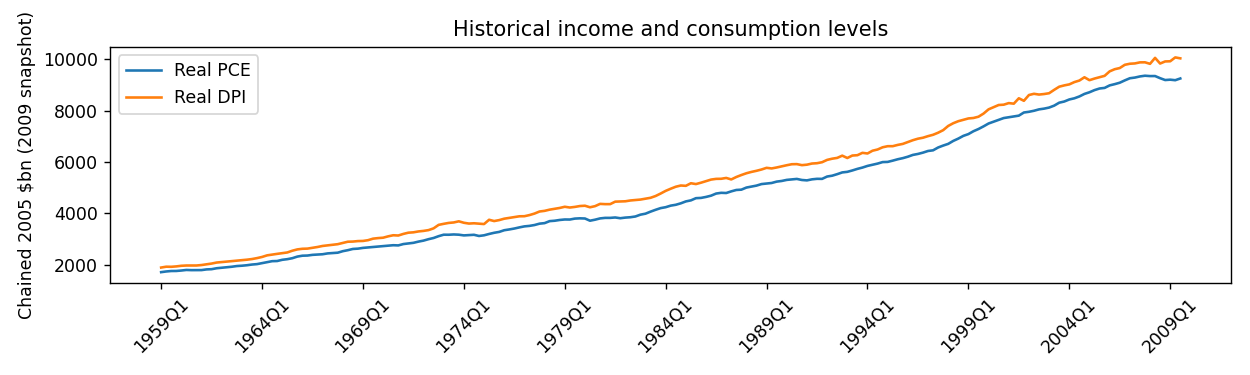

In [6]:
display(Image(filename='figures/01_income_consumption_levels.png'))

## 04. Data & Source Integrity

The frozen 203-row `statsmodels` U.S. macrodata snapshot has 1959Q1–2009Q3 observations, compiled from FRED and BLS with stated **access date 2009-12-15**. The access date is not an original publication date for each row. Levels are chained-2005-dollar billions at seasonally adjusted annual rates. Grade B for the bundled snapshot, grade A for official source/classification context, grade C for unverified qualitative sector exposure. The exact original quarterly FRED IDs and initial release timestamps are UNKNOWN.

In [7]:
register=pd.read_csv('data/source_register.csv');display(register[['source_id','grade','publisher','collection_or_access_date','observation_period','revision_or_vintage_policy']])

,source_id,grade,publisher,collection_or_access_date,observation_period,revision_or_vintage_policy
0,S1,B,statsmodels / FRED / BLS,2009-12-15,1959Q1-2009Q3,Single bundled retrospective snapshot; exact q...
1,S2,A,Federal Reserve Bank of St. Louis,2009-12-15,1959Q1-2009Q3,Original vintage archive exists in ALFRED but ...
2,S3,A,Bureau of Labor Statistics,2009-12-15,1959Q1-2009Q3,Historical releases and revisions not reconstr...
3,S4,A,Bureau of Economic Analysis,2026-10-28,2026,Current release schedule is NOT a historical v...
4,S5,A,U.S. Census Bureau,2026-10-28,2022,Modern classification used for context only
5,S6,C,Researcher constructed,2026-10-28,Illustrative not historical,Mechanism discussion only


In [8]:
print('Raw missing cells:',int(raw.isna().sum().sum()),'Duplicate quarters:',int(raw.date.duplicated().sum()));display(raw[['date','realcons','realdpi','realgdp','unemp']].head())

Raw missing cells: 0 Duplicate quarters: 0


,date,realcons,realdpi,realgdp,unemp
0,1959Q1,1707.4,1886.9,2710.349,5.8
1,1959Q2,1733.7,1919.7,2778.801,5.1
2,1959Q3,1751.8,1916.4,2775.488,5.3
3,1959Q4,1753.7,1931.3,2785.204,5.6
4,1960Q1,1770.5,1955.5,2847.699,5.2


## 05. Point-in-Time Availability

At formation `t`, all signal and control observations are from `t−1` or earlier, and targets are from `t` through `t+4`. Train labels are restricted to `j+4 <= t`. These rules prevent *mechanical observation-date leakage*, but the **2009 revised snapshot cannot verify historical information sets**. BEA release lags vary and early-vintage observations are not recovered. This is explicitly NOT PIT.

In [9]:
idx=20; t=int(panel.origin.iloc[idx]); print('Example origin',raw.date.iloc[t],'latest observed feature quarter',raw.date.iloc[t-1],'target endpoint',raw.date.iloc[t+4]);print('Feature',round(panel.factor.iloc[idx],4),'target',round(panel.target.iloc[idx],4))

Example origin 1965Q2 latest observed feature quarter 1965Q1 target endpoint 1966Q2
Feature 0.1886 target 6.1979


In [10]:
assert (pred.train_last_origin+4<=pred.origin).all();print('Purged OOS origins:',len(pred),'training sizes:',pred.train_n.min(),pred.train_n.max())

Purged OOS origins: 126 training sizes: 65 190


## 06. Factor Construction

Define `g_DPI(t)=100[ln(DPI(t))-ln(DPI(t−4))]` and `g_PCE(t)` analogously. The fixed factor is **F(t)=g_DPI(t−1)−g_PCE(t−1)** in log-percentage points. No whole-sample z-score or fitted exposure weights are used. The dependent variable is `Y(t,4)=100[ln(PCE(t+4))-ln(PCE(t))]`. Weight perturbations vary the two factor coefficients, and never use future data in fitting.

In [11]:
print('Factor summary:');display(panel[['factor','dpi_growth','cons_growth','target']].describe().round(3))

Factor summary:


,factor,dpi_growth,cons_growth,target
count,194.000,194.000,194.000,194.000
mean,-0.079,3.392,3.471,3.380
std,1.334,1.804,1.772,1.910
min,-3.734,-2.551,-1.594,-1.814
25%,-0.951,2.246,2.630,2.545
50%,-0.049,3.396,3.486,3.463
75%,0.865,4.380,4.688,4.688
max,2.842,8.039,7.774,7.774


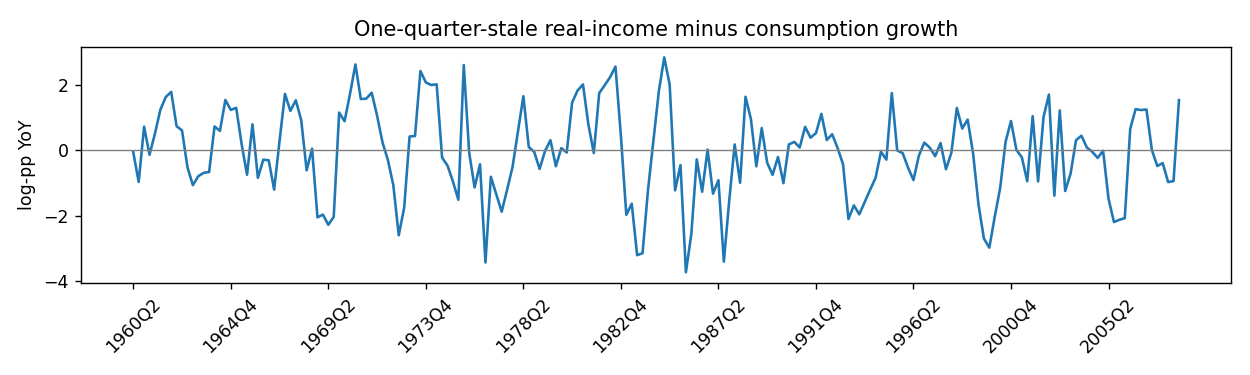

In [12]:
display(Image(filename='figures/02_income_gap_factor.png'))

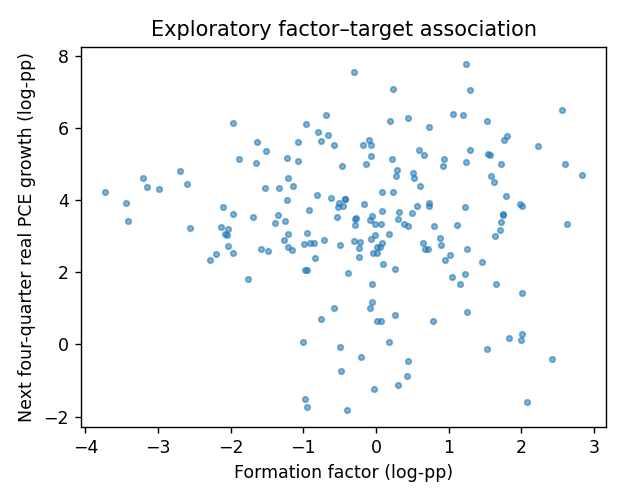

In [13]:
display(Image(filename='figures/03_factor_outcome_scatter.png'))

## 07. Exposure & Transmission

A rise in real disposable income relative to real PCE could raise future consumption through a delayed spending response; alternatively, households may save more or service debt. Sector mappings are **qualitative**, with UNKNOWN historical revenue shares. There is no company universe, no historical company filing exposure and no security cross-section. Consequently, leave-one-company-out, fundamental IC and long–short return spreads are **not applicable**, rather than silently treated as zero.

In [14]:
print('Sector mappings:',len(exposure),'numeric exposure weights observed:',exposure.quantitative_weight.ne('UNKNOWN').sum());display(exposure[['sector','reference','exposure_as_of']])

Sector mappings: 4 numeric exposure weights observed: 0


,sector,reference,exposure_as_of
0,Retail trade,https://www.census.gov/data/tables/2022/econ/e...,2022
1,Food services,https://www.census.gov/data/tables/2022/econ/e...,2022
2,Arts and recreation,https://www.census.gov/programs-surveys/econom...,2022
3,Other personal services,https://www.census.gov/programs-surveys/econom...,2022


## 08. Outcomes & Baselines

All models share the same purged expanding-window origins. Baselines: historical mean, one-quarter-stale PCE persistence scaled to horizon, consumption+unemployment AR Ridge, and multivariate Ridge controls (consumption growth, GDP growth, unemployment change, private investment growth). Challenger: controls plus the predeclared income–consumption gap. Ridge uses **training-only standardization** and fixed `alpha=2.0`; no hyperparameter search.

In [15]:
score=A.scorecard(pred);display(score.round(4))

,model,n_oos,rmse_log_pp,mae_log_pp,mean_error
0,macro_controls,126,1.7392,1.2878,0.5623
1,macro_plus_factor,126,1.7514,1.2915,0.5543
2,ar_ridge,126,1.8621,1.3582,0.4550
3,consumption_persistence,126,1.8742,1.3825,0.2064
4,historical_mean,126,1.9007,1.3782,0.6470
5,income_gap_only,126,1.9073,1.3841,0.6601


In [16]:
display(pred[['date','target','historical_mean','consumption_persistence','macro_controls','macro_plus_factor']].head(8).round(3))

,date,target,historical_mean,consumption_persistence,macro_controls,macro_plus_factor
0,1977Q2,5.144,4.069,4.394,4.070,4.324
1,1977Q3,4.612,4.067,4.034,3.750,3.930
2,1977Q4,3.919,4.068,3.931,3.477,3.601
3,1978Q1,3.841,4.061,4.134,3.242,3.152
4,1978Q2,1.666,4.077,3.579,3.255,2.986
5,1978Q3,2.225,4.084,5.144,3.230,3.200
6,1978Q4,1.688,4.082,4.612,3.369,3.364
7,1979Q1,1.011,4.079,3.919,3.320,3.517


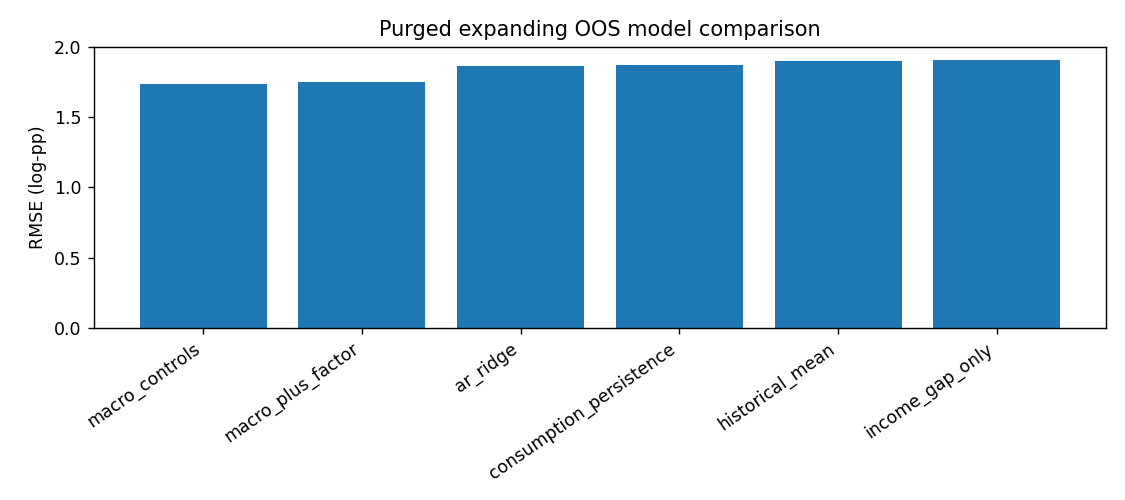

In [17]:
display(Image(filename='figures/04_oos_rmse.png'))

## 09. Empirical Findings

Primary effect is the RMSE difference `RMSE(macro controls) − RMSE(augmented)` in log-percentage points; positive values indicate improvement. Forecast errors are serially dependent because four-quarter targets overlap. Time-series factor–target correlation is descriptive and **not** a cross-sectional information coefficient. No equity return data are available.

In [18]:
gain=A.rmse(pred.target,pred.macro_controls)-A.rmse(pred.target,pred.macro_plus_factor);print('Primary OOS RMSE improvement (log-pp):',round(gain,6));print('In-sample time-series factor/target Pearson correlation:',round(panel[['factor','target']].corr().iloc[0,1],4))

Primary OOS RMSE improvement (log-pp): -0.012189
In-sample time-series factor/target Pearson correlation: -0.0249


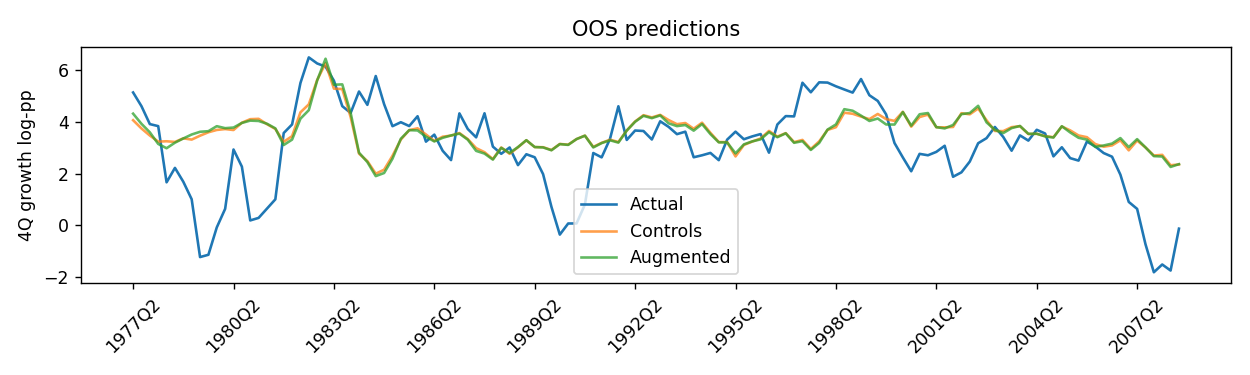

In [19]:
display(Image(filename='figures/05_oos_forecasts.png'))

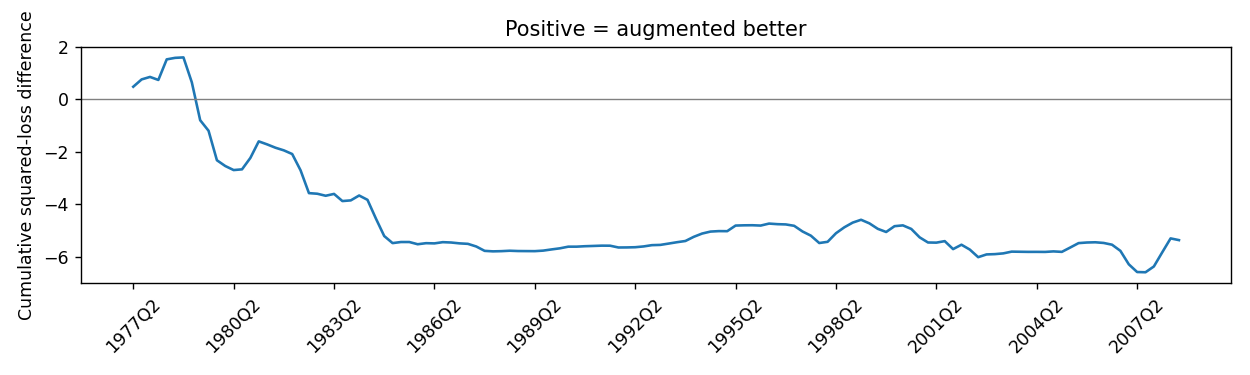

In [20]:
display(Image(filename='figures/06_cumulative_loss.png'))

## 10. Robustness & Placebos

The exploratory null shuffles intact eight-quarter blocks of the factor series, refits the expanding model 1,000 times, and reports the one-sided fraction of placebo gains at least as large as observed. Because blocks and the conditional null are approximate, this is **not** an exact randomization p-value. A 2,000-draw paired moving-block bootstrap resamples OOS forecast-error vectors in eight-quarter blocks. We also vary factor weights 1,000 times, perform ablations, vary horizons/lags and omit evaluation decades.

In [21]:
pl=pd.read_csv('results/block_placebo_1000.csv');print('Block placebo draws:',len(pl),'Exploratory upper-tail fraction:',metrics['placebo_tail_fraction_exploratory']);display(pl.null_gain_log_pp.describe().round(4))

Block placebo draws: 1000 Exploratory upper-tail fraction: 0.2947052947052947


count    1000.0000
mean       -0.0278
std         0.0345
min        -0.2297
25%        -0.0418
50%        -0.0230
75%        -0.0097
max         0.0879
Name: null_gain_log_pp, dtype: float64

In [22]:
bs=pd.read_csv('results/paired_block_bootstrap_2000.csv');print('Paired bootstrap draws:',len(bs),'95% CI:',metrics['bootstrap_ci95']);display(bs.gain_log_pp.describe().round(4))

Paired bootstrap draws: 2000 95% CI: [-0.030530578443057843, 0.006446582163417134]


count    2000.0000
mean       -0.0122
std         0.0095
min        -0.0445
25%        -0.0187
50%        -0.0121
75%        -0.0058
max         0.0189
Name: gain_log_pp, dtype: float64

In [23]:
ex=pd.read_csv('results/exposure_perturbation_1000.csv');print('Factor perturbations:',len(ex),'positive-gain fraction:',metrics['exposure_gain_positive_fraction']);display(ex.gain_log_pp.describe().round(4))

Factor perturbations: 1000 positive-gain fraction: 0.0


count    1000.0000
mean       -0.0121
std         0.0003
min        -0.0124
25%        -0.0123
50%        -0.0122
75%        -0.0119
max        -0.0112
Name: gain_log_pp, dtype: float64

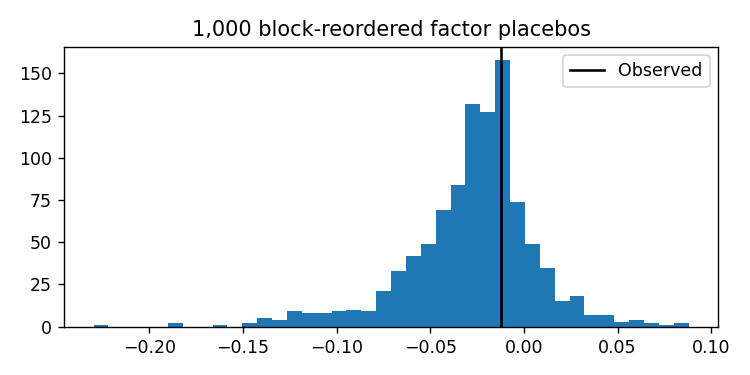

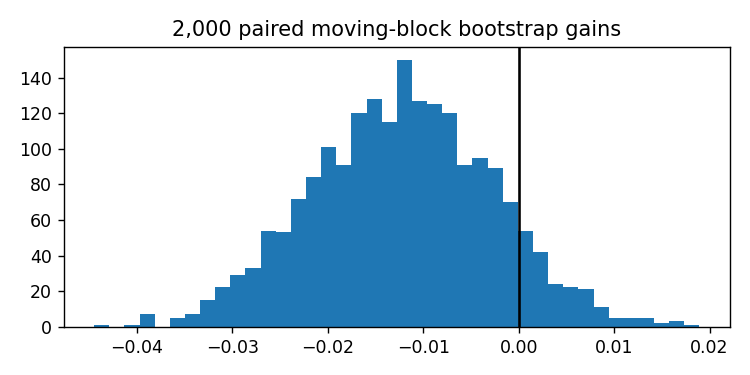

In [24]:
display(Image(filename='figures/07_block_placebo.png'));display(Image(filename='figures/08_bootstrap.png'))

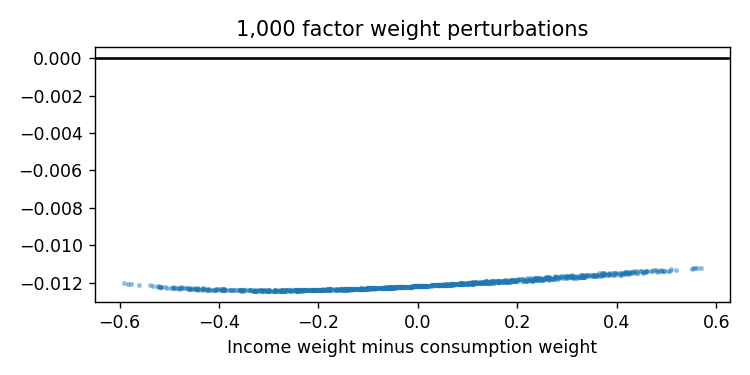

In [25]:
display(Image(filename='figures/09_exposure_sensitivity.png'))

In [26]:
abl=pd.read_csv('results/ablations.csv');display(abl.round(4))

,model,rmse,n
0,without_income,1.7392,126
1,without_unemployment,1.7786,126
2,without_gdp,1.8398,126
3,factor_only,1.9073,126


In [27]:
sensitivity=pd.read_csv('results/horizon_lag_sensitivity.csv');display(sensitivity.round(4))

,horizon_quarters,publication_buffer_quarters,n,control_rmse,augmented_rmse,gain
0,1,1,132,0.5960,0.6072,-0.0112
1,1,2,131,0.6063,0.6089,-0.0026
2,1,3,130,0.6376,0.6369,0.0007
3,2,1,130,0.9514,0.9723,-0.0209
4,2,2,129,1.0030,1.0046,-0.0016
5,2,3,128,1.0657,1.0608,0.0049
6,4,1,126,1.7392,1.7514,-0.0122
7,4,2,125,1.8571,1.8486,0.0085
8,4,3,124,1.9588,1.9523,0.0065


## 11. Regime Sensitivity

Breaks at 1984 and 2000 are **descriptive**, not optimized to select the most favorable regime. The evaluation set omits early decades due to minimum training. Leave-one-decade-out below excludes the named decade from OOS *scoring* while preserving the original historical training process; it is not a refit with that decade removed from training.

In [28]:
regime=pd.read_csv('results/regime_sensitivity.csv');display(regime.round(4))

,regime,n,gain
0,pre_1984,27,-0.0311
1,1984_1999,64,-0.0068
2,2000_2009,35,-0.0024


In [29]:
leave=pd.read_csv('results/leave_one_decade_out.csv');display(leave.round(4))

,excluded_decade,n,gain
0,1970,115,-0.0081
1,1980,86,-0.0064
2,1990,86,-0.0185
3,2000,91,-0.0163


## 12. Bias Audit & Verdict

**Look-ahead:** target purging and feature lags checked, but release-vintage leakage remains UNKNOWN. **Selection:** aggregate PCE was selected after reviewing existing industries; results are exploratory. **Survivorship:** not applicable to the aggregate series, but no historical firm universe exists. **Multiple testing:** several robustness choices reported without familywise adjustment; treat favorable findings cautiously. **Costs/capacity:** no tradable strategy was specified, so costs cannot be assessed. **Verdict:** use the observed OOS and uncertainty results, not the economic story, to determine whether the hypothesis survives; no investable equity alpha is claimed.

In [30]:
print('Control RMSE',round(metrics['control_rmse'],4),'Augmented RMSE',round(metrics['augmented_rmse'],4),'gain',round(metrics['gain_log_pp'],4));print('Bootstrap 95% CI',metrics['bootstrap_ci95']);print('NOT PIT:',not metrics['pit_verified'],'NO firm fundamentals:',not metrics['company_fundamentals_tested'],'NO equity returns:',not metrics['security_total_returns_tested'])

Control RMSE 1.7392 Augmented RMSE 1.7514 gain -0.0122
Bootstrap 95% CI [-0.030530578443057843, 0.006446582163417134]
NOT PIT: True NO firm fundamentals: True NO equity returns: True


## 13. Reproduction

From a clean checkout, install `requirements.txt`, run `python run_analysis.py`, then `python -m pytest -q tests`, and execute the notebook with `jupyter nbconvert --to notebook --execute research.ipynb --output executed.ipynb`. The committed notebook includes actual computed outputs. Numeric results are deterministic under the stated RNG seeds, library environment and frozen CSV; exact image bytes can vary with matplotlib/font versions.

In [31]:
import hashlib; frozen=Path('data/macrodata_statsmodels_2009_snapshot.csv');print('Frozen raw SHA256:',hashlib.sha256(frozen.read_bytes()).hexdigest());print('Source register rows:',len(register))

Frozen raw SHA256: 77bd9981786d6f633d96f35a09366765d1e8f056a8e11ba5dc2ec228161147b8
Source register rows: 6


In [32]:
print('Result files:',len(list(Path('results').glob('*'))),'Figures:',len(list(Path('figures').glob('*.png'))));print('Execution reproducibility requires original 2009 snapshot; no live API is called.')

Result files: 10 Figures: 9
Execution reproducibility requires original 2009 snapshot; no live API is called.


## 14. Next-Stage Protocol

Reconstruct vintage-specific real PCE, DPI, GDP and investment data using ALFRED and archived BEA release calendars. Pre-register factor/horizon before collecting a modern 2010–2026 holdout; estimate sector-specific retail, food-service and personal-service outcomes independently. Only after acquiring historical filing-dated company exposures and dividend-adjusted total returns should security-level IC, long–short spread, sector neutrality and costs be attempted. If vintage reconstruction fails, retain this as a retrospective falsification pilot.

In [33]:
print('Next data requirement: quarterly first-release vintage and timestamps for each observation.');print('Next independent outcomes: NAICS retail sales / food-service receipts; company revenue, EPS, total returns not yet available.')

Next data requirement: quarterly first-release vintage and timestamps for each observation.
Next independent outcomes: NAICS retail sales / food-service receipts; company revenue, EPS, total returns not yet available.


## 15. Sources & Artifacts

The exact source register contains original URLs, observation windows, access dates, source grades and revision limitations. Official BEA/Census/BLS pages are used only for provenance and qualitative context; the frozen `statsmodels` CSV is the **only quantitative source**. Files include `analysis.py`, `run_analysis.py`, tests, data, result tables, and nine diagnostic figures. See README for detailed interpretation and study.json for machine-readable paths.

In [34]:
display(register[['source_id','grade','resource','exact_url','original_publication_date']]);print('Research status:',metrics['status'])

,source_id,grade,resource,exact_url,original_publication_date
0,S1,B,US Macrodata bundled CSV,https://github.com/statsmodels/statsmodels/blo...,UNKNOWN
1,S2,A,FRED economic data,https://fred.stlouisfed.org/,UNKNOWN
2,S3,A,Official labor data,https://www.bls.gov/data/,UNKNOWN
3,S4,A,Personal Income and Outlays schedule,https://www.bea.gov/news/schedule/,UNKNOWN
4,S5,A,2022 NAICS Retail Trade sector,https://www.census.gov/data/tables/2022/econ/e...,2024-11-22
5,S6,C,Qualitative consumer-facing exposure mapping,local:data/sector_exposure_map.csv,2026-10-28


Research status: REPRODUCED RETROSPECTIVE CONSUMER-DEMAND MACRO PILOT — NOT PIT / NOT INDUSTRY-SPECIFIC / NOT EQUITY ALPHA


In [35]:
print('Final empirical decision: ', 'positive control-relative gain' if metrics['gain_log_pp']>0 else 'no control-relative improvement');print('Interpret against the best simple baseline, bootstrap interval and regime instability; never infer tradable equity alpha.')

Final empirical decision:  no control-relative improvement
Interpret against the best simple baseline, bootstrap interval and regime instability; never infer tradable equity alpha.
